# Projekt do wyzwania Wielkiej Ankiety Branży Data u Crappy Data

### Projekt ma na celu sprawdzenie czy większy wpływ na zarobki osób pracujących w branży Data mają lata doświadczenia zawodowego czy poziom wykształcenia.
Rozważano czy rozdzielić wykształcenie na grupy: wykształcenie kierunkowe (np informatyczne czy matematyczne) i nie (np humanistyczne czy przyrodnicze), ale zdecydowano się uwzględnić je wszystkie, ponieważ w zależności od stanowiska potrzebne są bardzo różnorodne umiejętności, również tak zwane umiejetności miękkie.

Na potrzeby tego projektu przy ustalaniu hierarchii wykształcenia przyjęto, że studia podyplomowe są wyżej niż magister oraz licencjat/inżynier (ponieważ osoby z obu tych grup mogą je ukończyć).

Projekt wykonano przy użyciu PySparka. 
Zarobki podane są w kwocie netto w złotówkach. 
Dane zostały udostępnione przez Crappy Data w formie plików csv. Do tej analizy użyto tylko dwóch (df_ogolne oraz df_organizacja_pracy). Dataset to zbiór odpowiedzi 296 osób pracujących w branży Data w ankiecie przeprowadzonej przez Crappy Data w 2025 roku.

### Import bibliotek

In [1]:
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[2]")
    .appName("wielka_ankieta")
    .getOrCreate()
)

In [2]:
spark.conf.set("spark.sql.repl.eagerEval.enabled", True)
spark.conf.set("spark.sql.repl.eagerEval.maxNumRows", 40)
spark.conf.set("spark.sql.repl.eagerEval.truncate", 100)

from pyspark.sql import functions as f
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Import danych z plików csv

In [3]:
ogolne = spark.read.csv('0.df_ogolne.csv', header = True, inferSchema = True)
organizacja_pracy = spark.read.csv('4.df_organizacja_pracy.csv', header = True, inferSchema = True)

### Przygotowanie danych

In [4]:
zestawienie = (
    ogolne.alias('o')
    .join(organizacja_pracy.alias('op'), on = 'id', how = 'left')
    .select(
        f.col('o.id'),
        f.col('stanowisko'),
        f.col('lata doświadczenia'),
        f.col('kierunek wykształcenia'),
        f.col('wykształcenie__studiowała/em, ale nie ukończyła/em'),
        f.col('wykształcenie__doktorat'),
        f.col('wykształcenie__inżynier'),
        f.col('wykształcenie__licencjat'),
        f.col('wykształcenie__magister'),
        f.col('wykształcenie__studia podyplomowe'),
        f.col('wykształcenie__zawodowe'),
        f.col('wykształcenie__średnie'),
        f.col('zarobki')
    )
)

In [5]:
zestawienie = (
    zestawienie
    .withColumn("najwyższe wykształcenie",
                f.when(f.col("wykształcenie__doktorat") == 1, "doktorat" )
                .when(f.col('wykształcenie__studia podyplomowe') == 1, 'podyplomowe')
                .when(f.col("wykształcenie__magister") == 1, "magister")
                .when((f.col("wykształcenie__licencjat") == 1) | (f.col("wykształcenie__inżynier") == 1), "licencjat / inżynier")
                .when(f.col('wykształcenie__zawodowe') == 1, 'zawodowe')
                .when(f.col('wykształcenie__średnie') == 1, 'średnie')
                .otherwise("brak")
               )
    .select(f.col('id'),
            f.col('stanowisko'),
            f.col('lata doświadczenia'),
            f.col('kierunek wykształcenia'),
            f.col('najwyższe wykształcenie'),
            f.col('zarobki')
           )
)

## Porównanie poziomu wykształcenia i średnich zarobków
Ze wszystkich wykresów usunięto wykształcenie zawodowe, ponieważ brak jest takich rekordów (osoby, które zaznaczyły wykształcenie zawodowe miały też wyższy stopień ukończonej edukacji, który został im przypisany).

In [6]:
średnie_zarobki_wg_poziomu_wyksz = (
    zestawienie
    .groupBy(f.col('najwyższe wykształcenie'))
    .agg(f.round(f.avg(f.col('zarobki')),2).alias('średnie zarobki'))
    .orderBy(f.col('średnie zarobki').desc())
)

display(średnie_zarobki_wg_poziomu_wyksz)

najwyższe wykształcenie,średnie zarobki
doktorat,12375.0
magister,9766.63
podyplomowe,9092.66
licencjat / inżynier,8998.65
brak,8500.0
średnie,7700.0


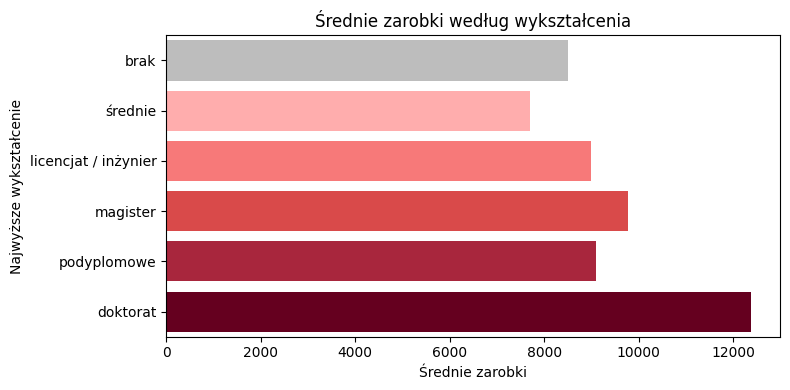

In [7]:
dane_wykres = średnie_zarobki_wg_poziomu_wyksz.toPandas()
kolory = {
    "brak": "#BDBDBD",
    "średnie": "#FFADAD",
    "licencjat / inżynier": "#F77979",
    "magister": "#D94A4A",
    "podyplomowe": "#A8263D",
    "doktorat": "#65001F"
}

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=dane_wykres,
    y="najwyższe wykształcenie",
    x="średnie zarobki",
    hue="najwyższe wykształcenie",
    order = kolory,
    dodge=False,
    errorbar=None,
    hue_order = kolory,
    palette=kolory,
    ax=ax,
    saturation=1
)

ax.set_title("Średnie zarobki według wykształcenia")
ax.set_ylabel('Najwyższe wykształcenie')
ax.set_xlabel("Średnie zarobki")

plt.tight_layout()
plt.show()

## Porównanie poziomu wykształcenia i średnich zarobków wg stanowiska

In [8]:
wykształcenie_vs_zarobki = (
    zestawienie
    .groupBy(f.col('stanowisko'), f.col('najwyższe wykształcenie'))
    .agg(f.round(f.avg(f.col('zarobki')),2).alias('średnie_zarobki'))
)

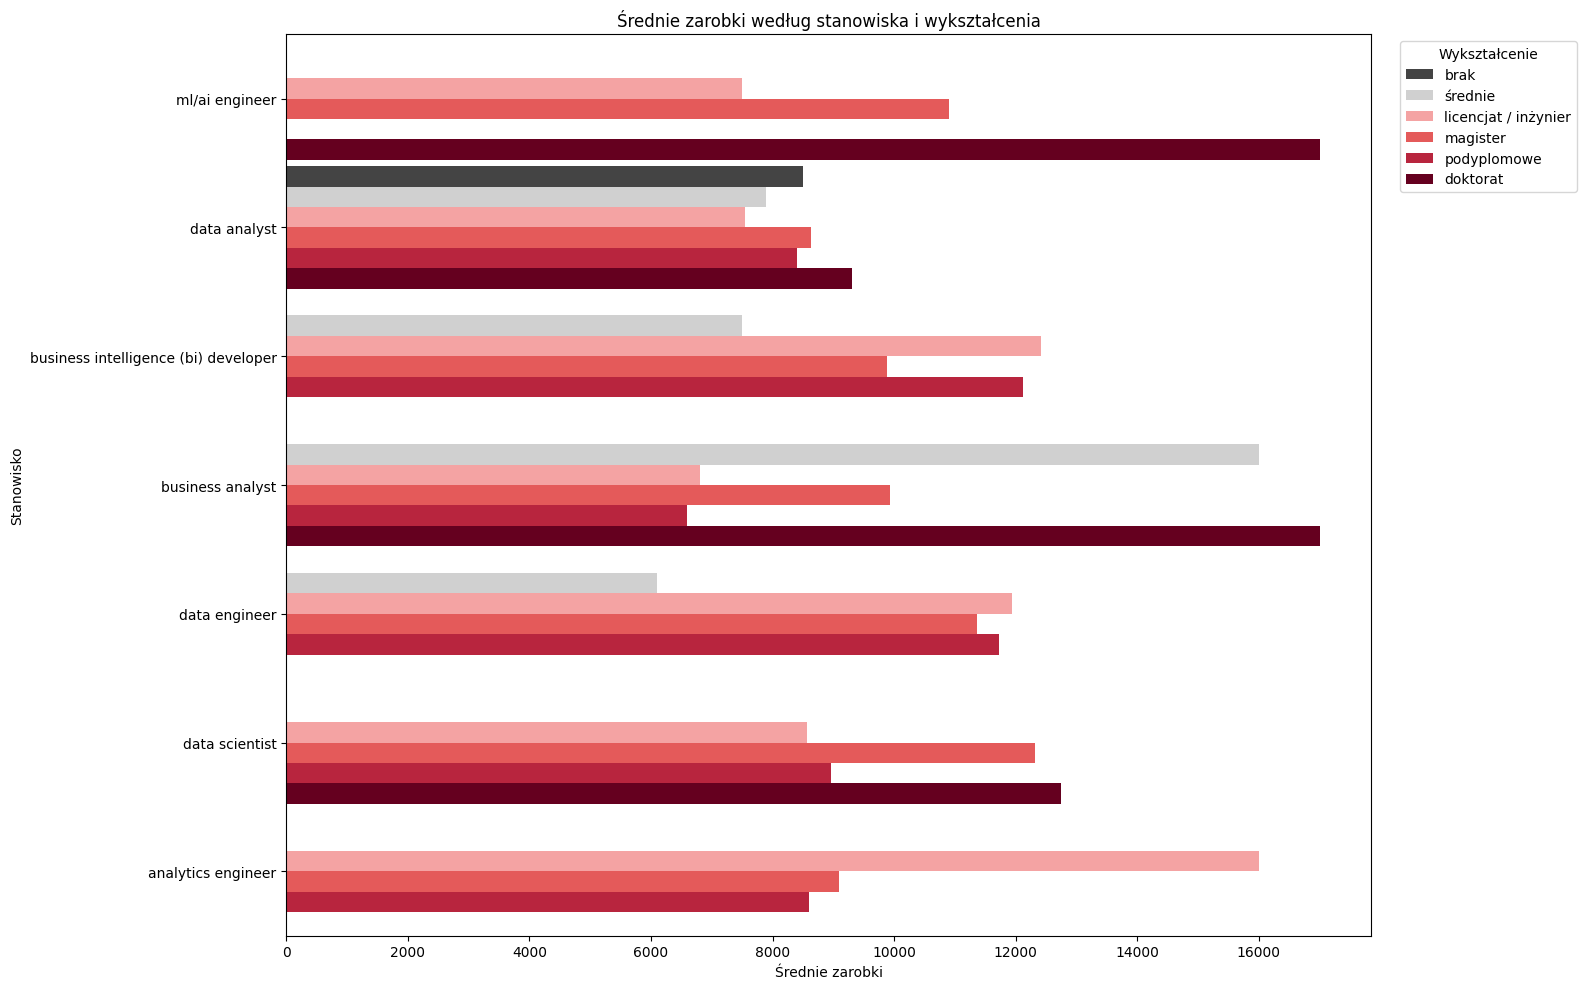

In [9]:
dane_wykres = wykształcenie_vs_zarobki.toPandas()

kolory = {
    "brak": "#444444",                             
    "średnie": "#D0D0D0",              
    "licencjat / inżynier": "#F4A3A3",  
    "magister": "#E45A5A",             
    "podyplomowe": "#B8253E",          
    "doktorat": "#65001F"             
}

fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=dane_wykres,
    y="stanowisko",
    x="średnie_zarobki",
    hue="najwyższe wykształcenie",
    hue_order=list(kolory),
    dodge=True,
    errorbar=None,
    palette=kolory,
    ax=ax,
    saturation=1,
    width = 0.95
)

ax.set_title("Średnie zarobki według stanowiska i wykształcenia")
ax.set_ylabel("Stanowisko")
ax.set_xlabel("Średnie zarobki")
ax.legend(
    title="Wykształcenie",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Porównanie lat doświadczenia i średnich zarobków

In [10]:
doświadczenie_vs_zarobki = (
    zestawienie
    .groupBy(f.col('lata doświadczenia'))
    .agg(f.round(f.avg(f.col('zarobki')),2).alias('średnie zarobki'))
)

In [11]:
display(doświadczenie_vs_zarobki)

lata doświadczenia,średnie zarobki
ponad 15 lat,9814.29
NULL,NULL
3–5 lat,8239.29
do 2 lat,6758.13
11-15 lat,9950.85
6–10 lat,10524.53


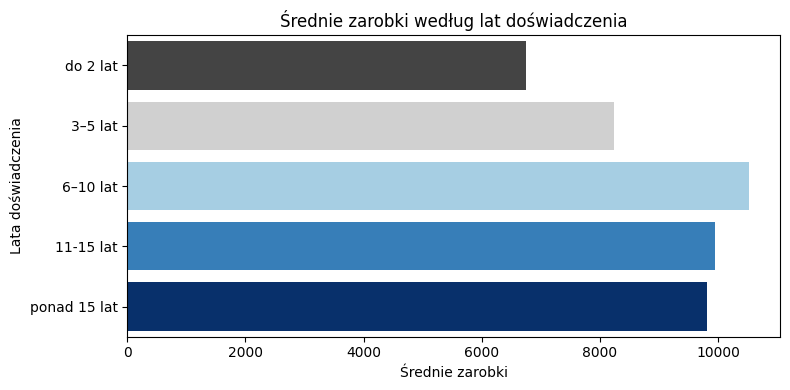

In [12]:
dane_wykres = doświadczenie_vs_zarobki.toPandas()
kolory = {
    "do 2 lat": "#444444",     
    "3–5 lat": "#D0D0D0",   
    "6–10 lat": "#A6CEE3",   
    "11-15 lat": "#377EB8",  
    "ponad 15 lat": "#08306B" 
}

fig, ax = plt.subplots(figsize=(8, 4))

sns.barplot(
    data=dane_wykres,
    y="lata doświadczenia",
    x="średnie zarobki",
    hue="lata doświadczenia",
    order = kolory,
    dodge=False,
    errorbar=None,
    hue_order = kolory,
    legend = False,
    palette=kolory,
    ax=ax,
    saturation=1
)

ax.set_title("Średnie zarobki według lat doświadczenia")
ax.set_ylabel('Lata doświadczenia')
ax.set_xlabel("Średnie zarobki")

plt.tight_layout()
plt.show()

## Porównanie lat doświadczenia i średnich zarobków wg stanowisk

In [13]:
doświadczenie_vs_zarobki_wg_stanowiska = (
    zestawienie
    .groupBy(f.col('stanowisko'), f.col('lata doświadczenia'))
    .agg(f.round(f.avg(f.col('zarobki')),2).alias('średnie zarobki'))
)

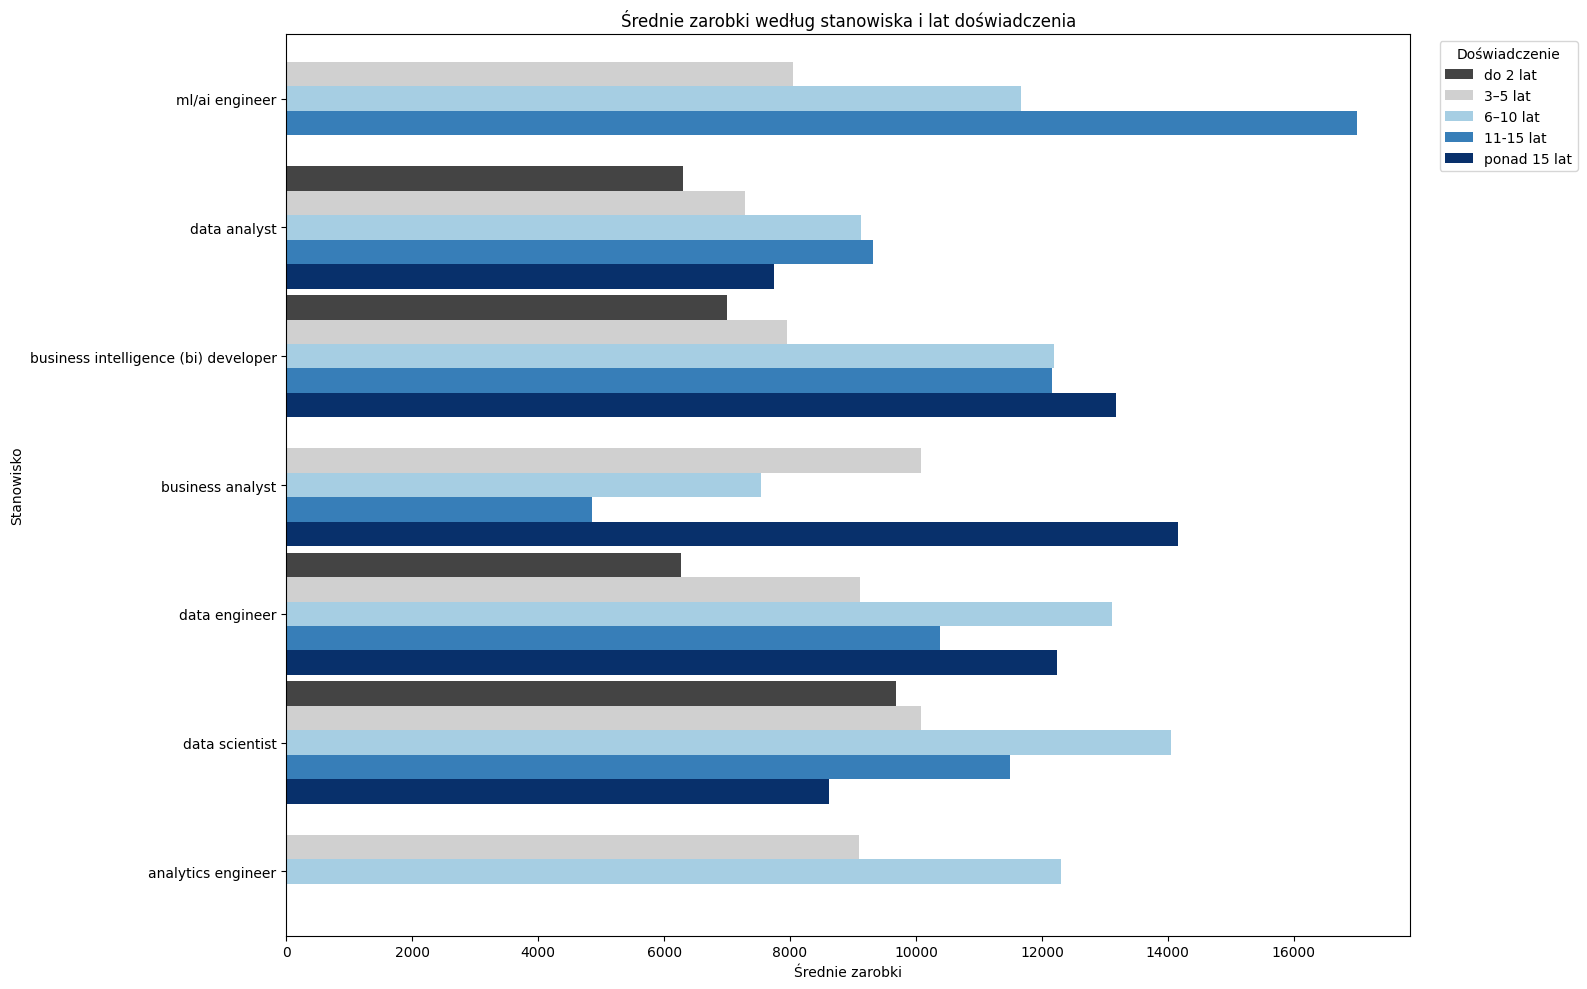

In [14]:
dane_wykres = doświadczenie_vs_zarobki_wg_stanowiska.toPandas()
kolory = {
    "do 2 lat": "#444444",     
    "3–5 lat": "#D0D0D0",   
    "6–10 lat": "#A6CEE3",   
    "11-15 lat": "#377EB8",  
    "ponad 15 lat": "#08306B" 
}
kolejnosc_stanowisk = [
    "ml/ai engineer",
    "data analyst",
    "business intelligence (bi) developer",
    "business analyst",
    "data engineer",
    "data scientist",
    "analytics engineer"
]
fig, ax = plt.subplots(figsize=(16, 10))

sns.barplot(
    data=dane_wykres,
    y="stanowisko",
    x="średnie zarobki",
    order=kolejnosc_stanowisk, 
    hue="lata doświadczenia",
    hue_order=list(kolory),
    dodge=True,
    errorbar=None,
    palette=kolory,
    ax=ax,
    saturation=1,
    width = 0.95
)

ax.set_title("Średnie zarobki według stanowiska i lat doświadczenia")
ax.set_ylabel("Stanowisko")
ax.set_xlabel("Średnie zarobki")
ax.legend(
    title="Doświadczenie",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Mapa ciepła wykształcenie vs doświadczenie

In [15]:
podsumowanie = (
    zestawienie
    .withColumn("lata doświadczenia", f.trim(f.regexp_replace("lata doświadczenia", r"[‐‑‒–—−]", "-")))
    .groupBy("lata doświadczenia", "najwyższe wykształcenie")
    .agg(f.round(f.avg("zarobki"),2).alias("średnie zarobki"),
        f.count("zarobki").alias("liczba osób")
    )
)

dane_heatmapa = podsumowanie.toPandas()

In [17]:
kolejnosc_doswiadczenia = ["do 2 lat", "3-5 lat", "6-10 lat", "11-15 lat", "ponad 15 lat"]
kolejnosc_wyksztalcenia = ["brak", "średnie", "licencjat / inżynier", "magister", "podyplomowe", "doktorat"]

macierz = (
    dane_heatmapa
    .pivot(
        index="lata doświadczenia",
        columns="najwyższe wykształcenie",
        values="średnie zarobki"
    )
    .reindex(
        index=kolejnosc_doswiadczenia,
        columns=kolejnosc_wyksztalcenia
    )
)

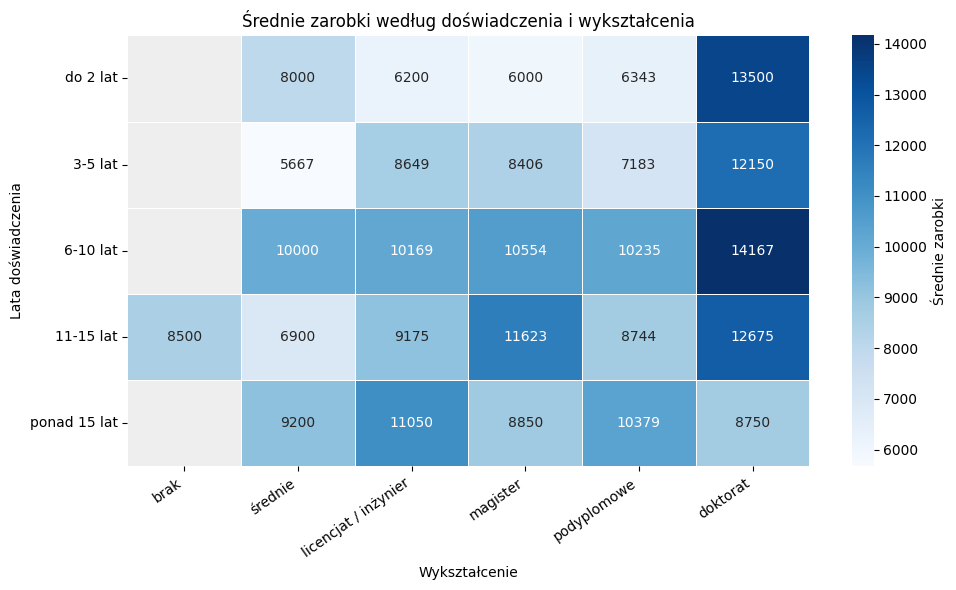

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor("#EEEEEE")

sns.heatmap(
    macierz,
    annot=True,                
    fmt=".0f",              
    cmap="Blues",       
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Średnie zarobki"},
    ax=ax
)

ax.set_title("Średnie zarobki według doświadczenia i wykształcenia")
ax.set_xlabel("Wykształcenie")
ax.set_ylabel("Lata doświadczenia")

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Wnioski

### *Najwyższe średnie zarobki w badanej grupie osiągają osoby z doktoratem oraz — w osobnym podziale według doświadczenia — osoby z doświadczeniem 6–10 lat. Zależności te różnią się jednak między stanowiskami.*

Im wyższe wykształcenie tym średnio wyższe zarobki, natomiast więcej lat doświadczenia niekoniecznie łączy się z wyższymi średnimi zarobkami. W datasecie lata doświadczenia są w zakresie od "do 2 lat" do "ponad 15 lat" - najwyższe średnio zarobki notują osoby o doświadczeniu w zakresie od 6 do 10 lat (nie najwyższym w skali). Nie jest to stwierdzenie prawdziwe dla wszystkich stanowisk, ale dla znacznej większości (jedyny wybija się tutaj buisness analyst, gdzie najdłuższe doświadczenie równa się najwyższym zarobkom).

Średnio najwięcej zarabiają osoby z doktoratem (powyżej 12 tys), na kolejnym miejscu są osoby z tytułem magistra (średnio nieco poniżej 10 tys). Najniższe średnie zarobki notują osoby z wykształceniem średnim (poniżej 8 tys). Wśród ankietowanych są również osoby, które nie zadeklarowały żadnego wykształcenia ('kategoria 'brak') i one notują średnie wykształcenie powyżej 8 tys.

Wśród stanowisk w których były osoby z doktoratem, to one zarabiały średnio najwięcej (ml/ai engineer - powyżej 16 tys, data analyst - ok 9 tys,  business analyst - powyżej 16 tys, data scientist - powyżej 12 tys). Natomiast wśród pozostałych stanowisk najwyższe średnie zarobki zadeklarowały osoby o wykształceniu  licencjat/inżynier (buisness intelligence (bi) developer - ponad 12 tys, data engineer - 12 tys, analytics engineer - 16 tys). 
Co ciekawe w kategorii business analyst na drugim miejscu pod kątem średnich zarobków po doktoracie plasują się osoby z wykształceniem średnim (średnio 16 tys).


Największą korelację lat doświadzcenia i zarobków można zauważyć na stanowisku business intelligence (bi) developer. W pozostałych przypadkach najczęściej najlepiej zarabiają osoby o doświadczeniu 6-10 lat (data engineer - ok 13 tys, data scientist - 14 tys oraz analytics engineer - ponad 12 tys) oraz 11-15 lat (ml/ai engineer - powyżej 16 tys, data analyst - ok 9 tys). Nieoczywista sytuacja jest zauważalna wśród business analystów -najwyższe średnie zarobki mają osoby o ponad 15 letnim doświadczeniu (14 tys), natomiast na drugim miejscu są osoby z przedziału 3-5 lat doświadczenia (10 tys). Podobnie zaskakujące są dane dotyczące data scientistów, gdyż tutaj osoby o małym doświadczeniu zarabiają więcej niż osoby o ponad 15 letnim doświadczeniu.
Najniższe zarobki w prawie wszystkich grupach notują osoby o małym doświadczeniu: do 2 lat lub 3-5 lat. 

Mapa ciepła potwierdza powyższe wnioski: najlepiej zarabiają osoby z doktoratem, z doświadczeniem 6-10 lat - najwyższa wartość 14 167 zł.


## Ograniczenia i dalsze kroki
W tej analizie nie wzięto pod uwagę poziomu stanowiska (seniority) co może zaburzać analizę, ponieważ uśredniamy zarobki menedżerów, seniorów, midów i juniorów. To mógłby być kolejny etap tej analizy - zejście w warstwę poziomu stanowiska. Kolejnym ograniczeniem jest mała grupa badanych, przez co na przykład na mapie ciepła niektóre komórki rezprezentują jedną osobę.

Aby pogłębić ta analizę można przyjrzeć się kierunkom wykształcenia badanych osób, również w rozbiciu na stanowiska, poziomowi stanowisk (seniority), a także porównać zarobki w zależności od rodzaju umowy (czy umowa B2B oznacza wyższe zarobki?). 